# LINEAR REGRESSION MODEL

### This Model will look into some flight data and then predicts the delay in the arrival of a flight

In [1]:
# if you get an error here, please try importing all the modules first
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler
from sklearn.model_selection import train_test_split
import seaborn as sns

## Preprocessing of data from flights.csv

Code to get the dataframe

In [2]:
data = pd.read_csv("flights.csv")
df = pd.DataFrame(data)
df

C:\Users\maxon\AppData\Local\Temp\ipykernel_30464\117169424.py:1: DtypeWarning: Columns (0: ORIGIN_AIRPORT, 1: DESTINATION_AIRPORT) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv("flights.csv")


,YEAR,MONTH,DAY,DAY_OF_WEEK,AIRLINE,FLIGHT_NUMBER,TAIL_NUMBER,ORIGIN_AIRPORT,DESTINATION_AIRPORT,SCHEDULED_DEPARTURE,...,ARRIVAL_TIME,ARRIVAL_DELAY,DIVERTED,CANCELLED,CANCELLATION_REASON,AIR_SYSTEM_DELAY,SECURITY_DELAY,AIRLINE_DELAY,LATE_AIRCRAFT_DELAY,WEATHER_DELAY
0,2015,1,1,4,AS,98,N407AS,ANC,SEA,5,...,408.0,-22.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
1,2015,1,1,4,AA,2336,N3KUAA,LAX,PBI,10,...,741.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
2,2015,1,1,4,US,840,N171US,SFO,CLT,20,...,811.0,5.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
3,2015,1,1,4,AA,258,N3HYAA,LAX,MIA,20,...,756.0,-9.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,2015,1,1,4,AS,135,N527AS,SEA,ANC,25,...,259.0,-21.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5819074,2015,12,31,4,B6,688,N657JB,LAX,BOS,2359,...,753.0,-26.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819075,2015,12,31,4,B6,745,N828JB,JFK,PSE,2359,...,430.0,-16.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819076,2015,12,31,4,B6,1503,N913JB,JFK,SJU,2359,...,432.0,-8.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
5819077,2015,12,31,4,B6,333,N527JB,MCO,SJU,2359,...,330.0,-10.0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


get info on the table

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5819079 entries, 0 to 5819078
Data columns (total 31 columns):
 #   Column               Dtype  
---  ------               -----  
 0   YEAR                 int64  
 1   MONTH                int64  
 2   DAY                  int64  
 3   DAY_OF_WEEK          int64  
 4   AIRLINE              str    
 5   FLIGHT_NUMBER        int64  
 6   TAIL_NUMBER          str    
 7   ORIGIN_AIRPORT       object 
 8   DESTINATION_AIRPORT  object 
 9   SCHEDULED_DEPARTURE  int64  
 10  DEPARTURE_TIME       float64
 11  DEPARTURE_DELAY      float64
 12  TAXI_OUT             float64
 13  WHEELS_OFF           float64
 14  SCHEDULED_TIME       float64
 15  ELAPSED_TIME         float64
 16  AIR_TIME             float64
 17  DISTANCE             int64  
 18  WHEELS_ON            float64
 19  TAXI_IN              float64
 20  SCHEDULED_ARRIVAL    int64  
 21  ARRIVAL_TIME         float64
 22  ARRIVAL_DELAY        float64
 23  DIVERTED             int64  
 24  CANCELLED

Get empty value

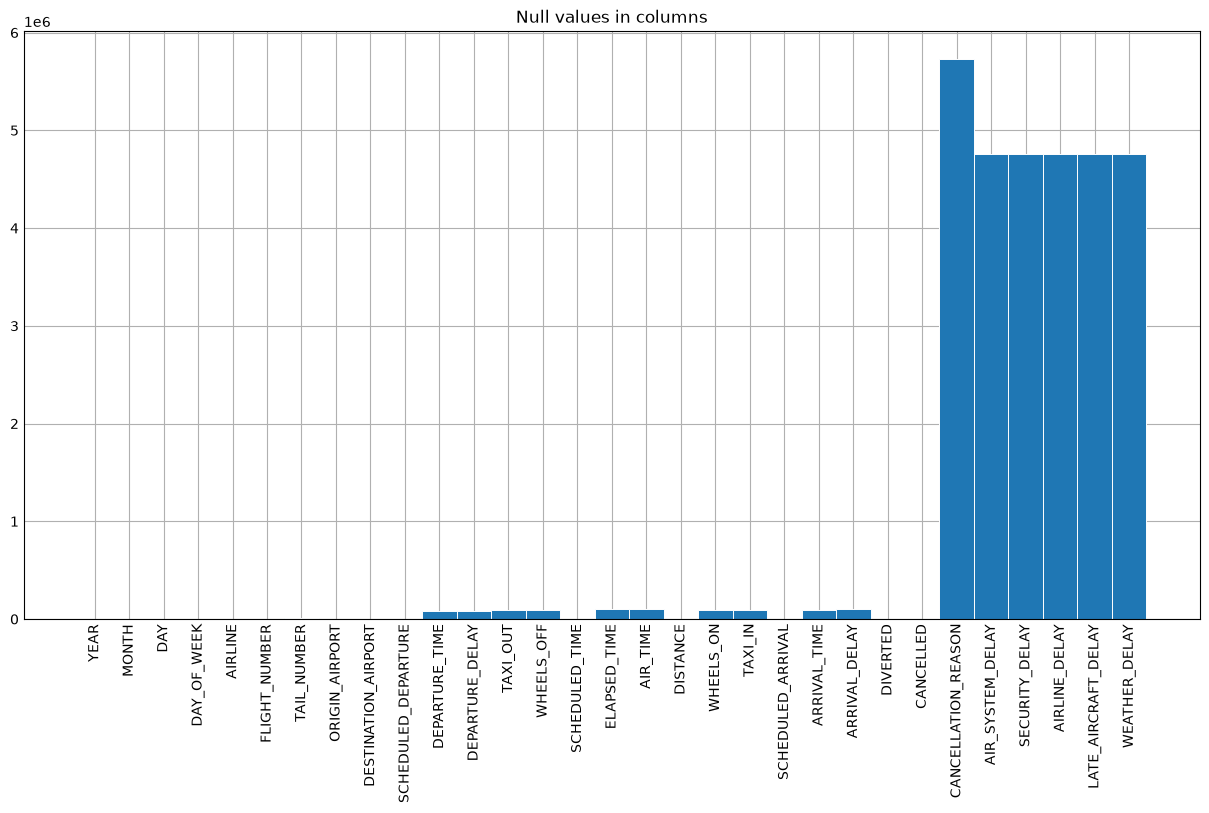

In [4]:
plt.style.use('_mpl-gallery')
x = df.isnull().sum().tolist()
fig, ax = plt.subplots(figsize=(12,6))
plt.xticks(rotation=90)
ax.bar(df.columns,x, width=1, edgecolor="white", linewidth=0.7)
plt.title("Null values in columns")
plt.show()

Get corellation matrix

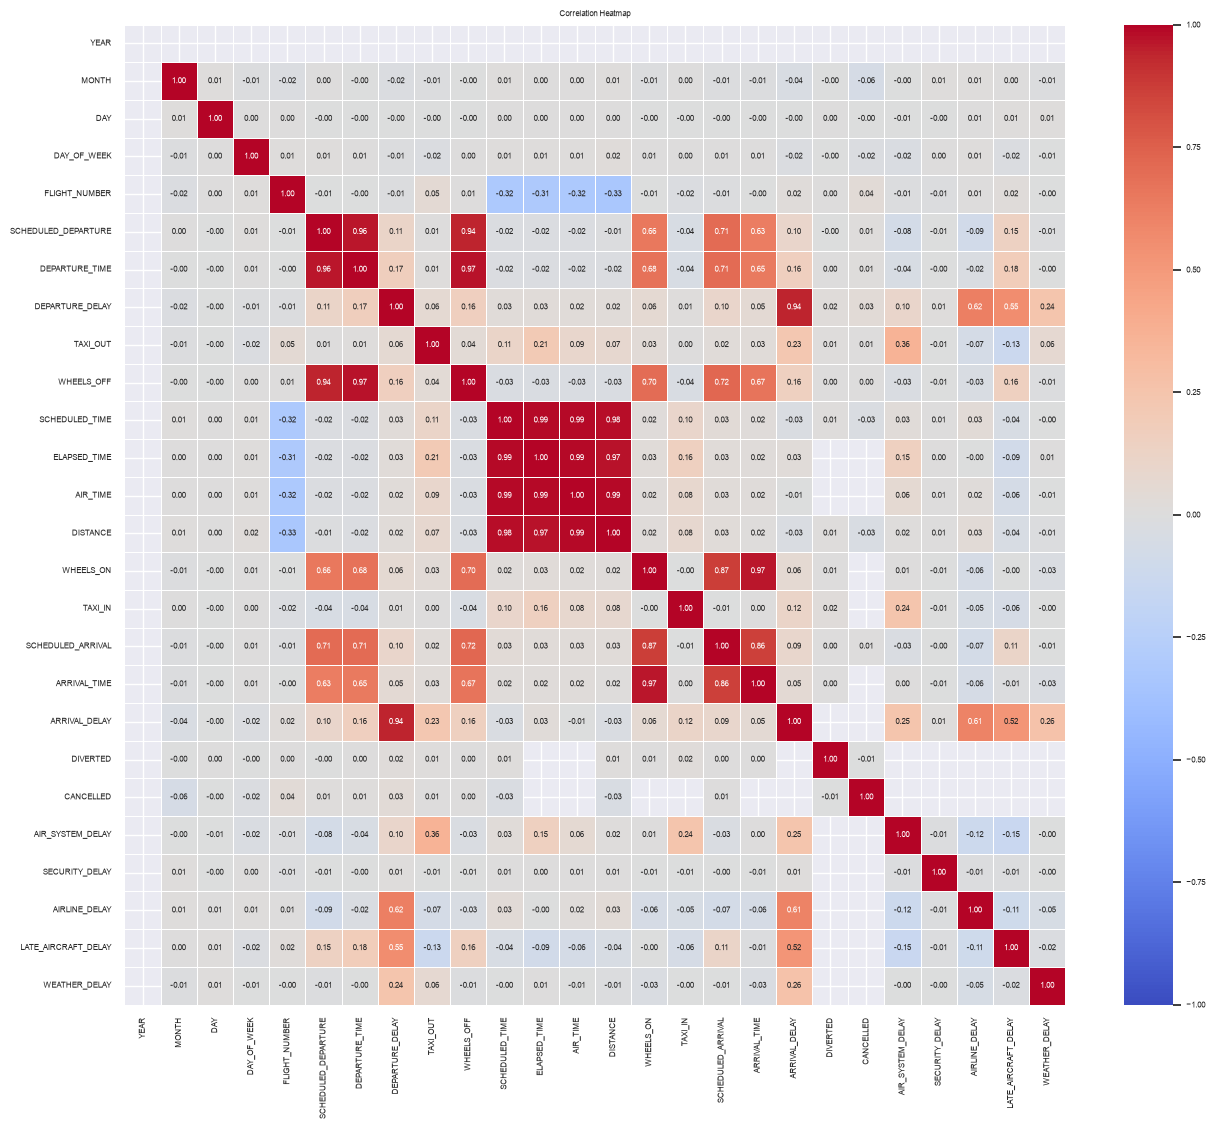

In [5]:
plt.figure(figsize=(12, 10))
sns.set_theme(font_scale=0.5)
dfcorr = df.corr(numeric_only=True)
sns.heatmap(dfcorr, vmin=-1, vmax=1, center=0,cmap="coolwarm",
            annot=True,fmt=".2f", linewidths=0.5 )
plt.xticks(rotation=90)
plt.title("Correlation Heatmap")
plt.show()

get all the null values

In [6]:
df.isnull().sum()

YEAR                         0
MONTH                        0
DAY                          0
DAY_OF_WEEK                  0
AIRLINE                      0
FLIGHT_NUMBER                0
TAIL_NUMBER              14721
ORIGIN_AIRPORT               0
DESTINATION_AIRPORT          0
SCHEDULED_DEPARTURE          0
DEPARTURE_TIME           86153
DEPARTURE_DELAY          86153
TAXI_OUT                 89047
WHEELS_OFF               89047
SCHEDULED_TIME               6
ELAPSED_TIME            105071
AIR_TIME                105071
DISTANCE                     0
WHEELS_ON                92513
TAXI_IN                  92513
SCHEDULED_ARRIVAL            0
ARRIVAL_TIME             92513
ARRIVAL_DELAY           105071
DIVERTED                     0
CANCELLED                    0
CANCELLATION_REASON    5729195
AIR_SYSTEM_DELAY       4755640
SECURITY_DELAY         4755640
AIRLINE_DELAY          4755640
LATE_AIRCRAFT_DELAY    4755640
WEATHER_DELAY          4755640
dtype: int64

removing rows that arent wouldnt be provided for the final data and empty rows

In [7]:
df1 = df.copy()
df1.drop(columns=['CANCELLATION_REASON',
                   'DIVERTED',
                   'CANCELLED',
                   'ARRIVAL_TIME',
                   'YEAR',
                   'FLIGHT_NUMBER',
                   'TAIL_NUMBER',
                   'AIR_SYSTEM_DELAY',
                   'DEPARTURE_TIME',
                   'AIR_SYSTEM_DELAY',
                   'SECURITY_DELAY',
                   'AIRLINE_DELAY',
                   'LATE_AIRCRAFT_DELAY',
                   'WEATHER_DELAY',
                   'WHEELS_ON',
                   'TAXI_IN',
                   'TAXI_OUT',
                   'WHEELS_OFF',
                   'ELAPSED_TIME',
                   'AIR_TIME'], inplace = True)
df1.dropna(subset=['ARRIVAL_DELAY'], inplace=True)
print("After removing rows and columns:\n", df1.isnull().sum(), sep="")

After removing rows and columns:
MONTH                  0
DAY                    0
DAY_OF_WEEK            0
AIRLINE                0
ORIGIN_AIRPORT         0
DESTINATION_AIRPORT    0
SCHEDULED_DEPARTURE    0
DEPARTURE_DELAY        0
SCHEDULED_TIME         0
DISTANCE               0
SCHEDULED_ARRIVAL      0
ARRIVAL_DELAY          0
dtype: int64


Converting HHMM format to minutes and using one hot encoding for some columns

In [8]:
def hhmm_to_minutes(val):
    val = int(val)
    if val == 2400: 
        val = 0
    return (val // 100) * 60 + (val % 100)
df1["SCH_DEP_MINUTES"] = df1["SCHEDULED_DEPARTURE"].apply(hhmm_to_minutes)
df1["SCH_ARR_MINUTES"] = df1["SCHEDULED_ARRIVAL"].apply(hhmm_to_minutes)
df1 = df1.drop(columns=["SCHEDULED_DEPARTURE","SCHEDULED_ARRIVAL"])
df1.info()


<class 'pandas.DataFrame'>
Index: 5714008 entries, 0 to 5819078
Data columns (total 12 columns):
 #   Column               Dtype  
---  ------               -----  
 0   MONTH                int64  
 1   DAY                  int64  
 2   DAY_OF_WEEK          int64  
 3   AIRLINE              str    
 4   ORIGIN_AIRPORT       object 
 5   DESTINATION_AIRPORT  object 
 6   DEPARTURE_DELAY      float64
 7   SCHEDULED_TIME       float64
 8   DISTANCE             int64  
 9   ARRIVAL_DELAY        float64
 10  SCH_DEP_MINUTES      int64  
 11  SCH_ARR_MINUTES      int64  
dtypes: float64(3), int64(6), object(2), str(1)
memory usage: 566.7+ MB


Splitting into test and train data

In [9]:
y = df1['ARRIVAL_DELAY'].values
X_df = df1.drop(columns=['ARRIVAL_DELAY'])

X_train, X_test, result_train, result_test = train_test_split(X_df, y, test_size=0.2, random_state=1)
train_df = X_train.copy()
train_df['ARRIVAL_DELAY'] = result_train


Encoding Columns with large different values

In [10]:
global_mean = train_df['ARRIVAL_DELAY'].mean()
origin_means = train_df.groupby('ORIGIN_AIRPORT')['ARRIVAL_DELAY'].mean().to_dict()
dest_means = (train_df.groupby('DESTINATION_AIRPORT')['ARRIVAL_DELAY'].mean().to_dict())

for dataset in [X_train, X_test]:
  dataset['ORIGIN_ENCODED'] = (dataset['ORIGIN_AIRPORT'].map(origin_means).fillna(global_mean))
  dataset['DESTINATION_ENCODED'] = (dataset['DESTINATION_AIRPORT'].map(dest_means).fillna(global_mean))

X_train = X_train.drop(columns=['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT'])
X_test = X_test.drop(columns=['ORIGIN_AIRPORT', 'DESTINATION_AIRPORT'])

Using one hot encoder for Columns with lesser Data

In [11]:
cat_cols = ['AIRLINE', 'MONTH', 'DAY', 'DAY_OF_WEEK']
OHE = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

train_cat = OHE.fit_transform(X_train[cat_cols])
test_cat = OHE.transform(X_test[cat_cols])

train_cat_df = pd.DataFrame(train_cat, columns=OHE.get_feature_names_out(cat_cols), index=X_train.index)
test_cat_df = pd.DataFrame(test_cat, columns=OHE.get_feature_names_out(cat_cols), index=X_test.index)

X_train = pd.concat([X_train.drop(columns=cat_cols), train_cat_df], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_cols), test_cat_df], axis=1)

Using Spline for time

In [12]:
spline = SplineTransformer(n_knots=5, degree=3, include_bias=False)

dep_train_splines = spline.fit_transform(X_train[['SCH_DEP_MINUTES']])
dep_test_splines = spline.transform(X_test[['SCH_DEP_MINUTES']])

arr_train_splines = spline.fit_transform(X_train[['SCH_ARR_MINUTES']])
arr_test_splines = spline.transform(X_test[['SCH_ARR_MINUTES']])

dep_train_df = pd.DataFrame(dep_train_splines,columns=[f'SCH_DEP_SPLINE_{i}' for i in range(dep_train_splines.shape[1])],index=X_train.index)
dep_test_df = pd.DataFrame(dep_test_splines,columns=[f'SCH_DEP_SPLINE_{i}' for i in range(dep_test_splines.shape[1])],index=X_test.index)

arr_train_df = pd.DataFrame(arr_train_splines, columns=[f'SCH_ARR_SPLINE_{i}' for i in range(arr_train_splines.shape[1])],index=X_train.index)
arr_test_df = pd.DataFrame(arr_test_splines,columns=[f'SCH_ARR_SPLINE_{i}' for i in range(arr_test_splines.shape[1])],index=X_test.index)

X_train = pd.concat([X_train.drop(columns=['SCH_DEP_MINUTES', 'SCH_ARR_MINUTES']),dep_train_df,arr_train_df],axis=1)
X_test = pd.concat([X_test.drop(columns=['SCH_DEP_MINUTES', 'SCH_ARR_MINUTES']),dep_test_df,arr_test_df],axis=1)

X_train = X_train.select_dtypes(include=[np.number]).values
X_test = X_test.select_dtypes(include=[np.number]).values

applying Standard Scaler

In [13]:
scaler = StandardScaler()
data_train_scaled = scaler.fit_transform(X_train)
data_test_scaled = scaler.transform(X_test)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)
print("Training Result:", result_train.shape)
print("Testing Result:", result_test.shape)

Training Data: (4571206, 81)
Testing Data: (1142802, 81)
Training Result: (4571206,)
Testing Result: (1142802,)


## Linear Regression

setting model parameters

In [14]:
n_samples, n_features = data_train_scaled.shape
weights = np.zeros(n_features)
bias = 0.0
learning_rate = 0.1
n_iterations = 500
cost_history = []

Training of Model

In [15]:
print('Training Model:')
for i in range(n_iterations):
  y_pred = np.dot(data_train_scaled, weights) + bias
  dw = (2 / n_samples) * np.dot(data_train_scaled.T, (y_pred - result_train))
  db = (2 / n_samples) * np.sum(y_pred - result_train)
  weights -= learning_rate * dw
  bias -= learning_rate * db
  cost = np.mean((y_pred - result_train) ** 2)
  cost_history.append(cost)
  if (i + 1) % 50 == 0:
    print(f'Iteration {i+1}/{n_iterations} | Cost (MSE): {cost:.4f}')

Training Model:
Iteration 50/500 | Cost (MSE): 155.5941
Iteration 100/500 | Cost (MSE): 154.9830
Iteration 150/500 | Cost (MSE): 154.5199
Iteration 200/500 | Cost (MSE): 154.1630
Iteration 250/500 | Cost (MSE): 153.8865
Iteration 300/500 | Cost (MSE): 153.6718
Iteration 350/500 | Cost (MSE): 153.5051
Iteration 400/500 | Cost (MSE): 153.3755
Iteration 450/500 | Cost (MSE): 153.2748
Iteration 500/500 | Cost (MSE): 153.1965


Evaluation of model

In [16]:
train_predictions = np.dot(data_train_scaled, weights) + bias
test_predictions = np.dot(data_test_scaled, weights) + bias

train_mse = np.mean((train_predictions - result_train) ** 2)
test_mse = np.mean((test_predictions - result_test) ** 2)
test_mae = np.mean(np.abs(test_predictions - result_test))

print('Model Evaluation')
print(f'Train MSE: {train_mse:.4f}')
print(f'Test MSE:  {test_mse:.4f}')
print(f'Test MAE:  {test_mae:.4f}')

Model Evaluation
Train MSE: 153.1951
Test MSE:  153.1949
Test MAE:  8.6417


Graph of the cost vs the iteration

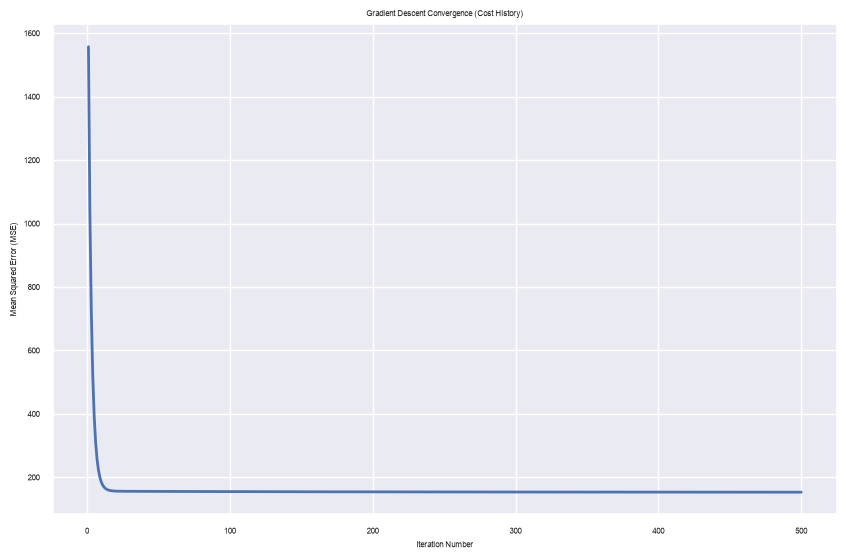

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, n_iterations + 1), cost_history, color='b', linewidth=2)
plt.title('Gradient Descent Convergence (Cost History)')
plt.xlabel('Iteration Number')
plt.ylabel('Mean Squared Error (MSE)')
plt.grid(True)
plt.show()

Comparison with Scikitlearn

In [18]:
sk_model = LinearRegression()
sk_model.fit(data_train_scaled, result_train)
sk_train_preds = sk_model.predict(data_train_scaled)
sk_test_preds = sk_model.predict(data_test_scaled)
sk_train_mse = np.mean((sk_train_preds - result_train) ** 2)
sk_test_mse = np.mean((sk_test_preds - result_test) ** 2)
sk_test_mae = np.mean(np.abs(sk_test_preds - result_test))
print(f'Custom GD Train MSE: {train_mse:.4f} | Sklearn Train MSE:'f' {sk_train_mse:.4f}')
print(f'Custom GD Test MSE:  {test_mse:.4f} | Sklearn Test MSE:'f' {sk_test_mse:.4f}')
print(f'Custom GD Test MAE:  {test_mae:.4f} | Sklearn Test MAE:'f' {sk_test_mae:.4f}')

Custom GD Train MSE: 153.1951 | Sklearn Train MSE: 152.8880
Custom GD Test MSE:  153.1949 | Sklearn Test MSE: 152.8690
Custom GD Test MAE:  8.6417 | Sklearn Test MAE: 8.6244


# ==================|END OF FILE|==================